# Team T085 · Section E · Project 26
Phase 1: Machine Learning

The expanded run reuses the previously inspected test partition. Training-only selection and validation-only robustness are preserved; this is not a fresh independent holdout.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
assert (ROOT/'src').exists(), 'Start Jupyter in the project folder.'
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
TABLES=ROOT/'results/tables'
FIGURES=ROOT/'results/figures'
def table(name): return pd.read_csv(TABLES/name)
def figure(name): display(Image(filename=str(FIGURES/name)))


## Model-independent metrics and frozen policies
Owner: Bhumi. Validate strict score>threshold policies at 0.1%,0.5%,1%,5% FPR, then apply frozen cutoffs to test. Capacity ranking separately reviews top fractions or top100. The test set has already been inspected in the initial run; disclose reuse.

,model,split,average_precision,pr_auc_trapezoidal,roc_auc,base_rate,ap_ci_lower,ap_ci_upper
0,gmm,validation,0.629867,0.628444,0.940519,0.001001,NaN,NaN
1,gmm,test,0.582203,0.578669,0.918662,0.001317,0.463446,0.712348
2,isolation_forest,validation,0.027381,0.026441,0.942014,0.001001,NaN,NaN
3,isolation_forest,test,0.053800,0.052400,0.951951,0.001317,0.039910,0.071807
4,pca,validation,0.069170,0.067247,0.958129,0.001001,NaN,NaN
5,pca,test,0.157348,0.154011,0.964220,0.001317,0.121233,0.207970
6,approx_ocsvm,validation,0.001243,0.001218,0.601779,0.001001,NaN,NaN
7,approx_ocsvm,test,0.001431,0.001409,0.541137,0.001317,0.001305,0.001602


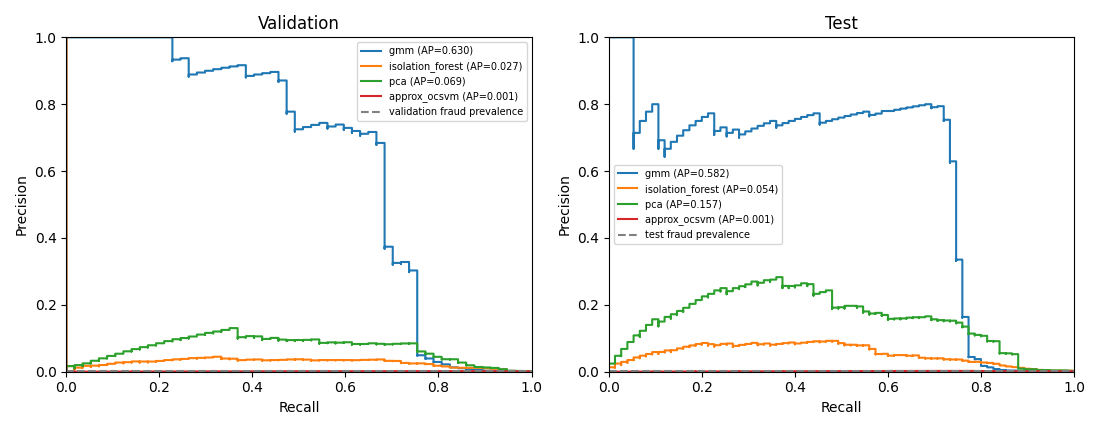

In [2]:
display(table('ranking_metrics.csv').round(6))
figure('pr_curves.png')

,model,split,fpr_budget,threshold,tp,fp,fn,tn,recall,fpr,precision,flagged,review_fraction
4,gmm,test,0.001,90.566273,55,29,20,56857,0.733333,0.000510,0.654762,84,0.001475
5,gmm,test,0.005,63.548622,57,175,18,56711,0.760000,0.003076,0.245690,232,0.004073
6,gmm,test,0.010,57.143619,58,324,17,56562,0.773333,0.005696,0.151832,382,0.006706
7,gmm,test,0.050,35.285345,60,2082,15,54804,0.800000,0.036600,0.028011,2142,0.037605


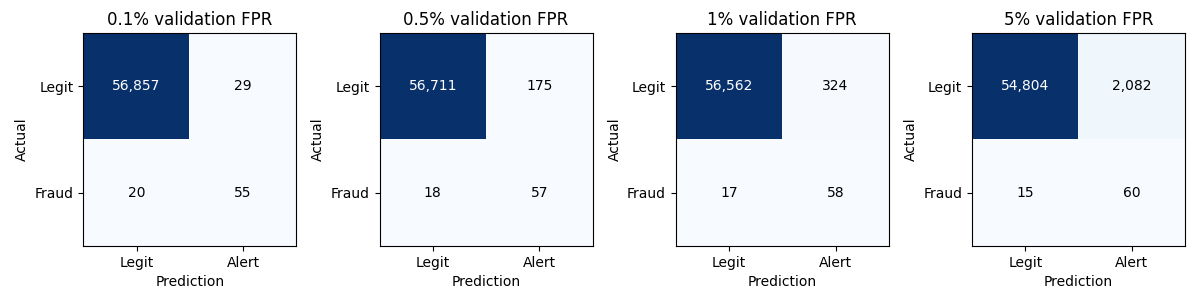

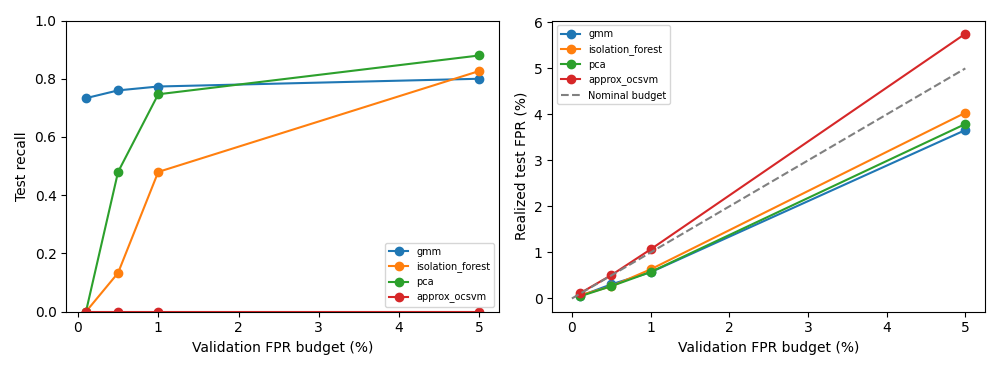

In [3]:
ops=table('operating_points.csv')
display(ops[(ops.model=='gmm')&(ops.split=='test')].round(6))
figure('gmm_confusion_matrices.png')
figure('threshold_tradeoffs.png')

In [4]:
display(table('review_capacity.csv').query("split=='test'").round(6))
display(table('review_workload.csv').query("model=='gmm' and split=='test'").round(6))
assert (ops[ops.split=='validation'].fpr<=ops[ops.split=='validation'].fpr_budget+1e-12).all()
row=ops[(ops.model=='gmm')&(ops.split=='test')&np.isclose(ops.fpr_budget,.005)].iloc[0]
assert np.isclose(row.recall,row.tp/(row.tp+row.fn))
assert np.isclose(row.precision,row.tp/(row.tp+row.fp))
assert np.isclose(row.fpr,row.fp/(row.fp+row.tn))
print('Confusion-count identities and validation FPR constraints verified.')

,model,split,policy,capacity_fraction,k,tp,precision_at_k,recall_at_k
4,gmm,test,fraction,0.001,56,43,0.767857,0.573333
5,gmm,test,fraction,0.005,284,57,0.200704,0.760000
6,gmm,test,fraction,0.010,569,58,0.101933,0.773333
7,gmm,test,count,NaN,100,56,0.560000,0.746667
12,isolation_forest,test,fraction,0.001,56,0,0.000000,0.000000
13,isolation_forest,test,fraction,0.005,284,24,0.084507,0.320000
14,isolation_forest,test,fraction,0.010,569,42,0.073814,0.560000
15,isolation_forest,test,count,NaN,100,2,0.020000,0.026667
20,pca,test,fraction,0.001,56,8,0.142857,0.106667
21,pca,test,fraction,0.005,284,45,0.158451,0.600000


,model,split,fpr_budget,threshold,tp,fp,fn,tn,recall,fpr,precision,flagged,review_fraction,false_positives_per_fraud,reviews_per_fraud,no_frauds_caught
4,gmm,test,0.001,90.566273,55,29,20,56857,0.733333,0.000510,0.654762,84,0.001475,0.527273,1.527273,False
5,gmm,test,0.005,63.548622,57,175,18,56711,0.760000,0.003076,0.245690,232,0.004073,3.070175,4.070175,False
6,gmm,test,0.010,57.143619,58,324,17,56562,0.773333,0.005696,0.151832,382,0.006706,5.586207,6.586207,False
7,gmm,test,0.050,35.285345,60,2082,15,54804,0.800000,0.036600,0.028011,2142,0.037605,34.700000,35.700000,False


Confusion-count identities and validation FPR constraints verified.


In [5]:
from src.metrics import evaluate_scores, load_thresholds
with np.load(ROOT/'data/processed/split_indices.npz') as ids:
    order=ids['test']
from src.data import load_raw
raw=load_raw(ROOT/'data/raw/creditcard.csv')
y=raw.loc[order,'Class'].to_numpy()
s=np.load(ROOT/'results/scores/gmm_test.npz')['score']
result=evaluate_scores(y,s,thresholds=[load_thresholds(ROOT/'results/tables/thresholds_frozen_on_validation.csv').query("model=='gmm' and fpr_budget==0.005").threshold.iloc[0]],review_fractions=[.005],review_counts=[100])
print(result)
assert result['operating_points'][0]['tp']==row.tp

{'ranking': {'average_precision': 0.5822028005222633, 'pr_auc_trapezoidal': 0.5786691473427593, 'roc_auc': 0.9186623539476614, 'base_rate': np.float64(0.0013166903670932743)}, 'operating_points': [{'threshold': 63.548622253312324, 'tp': 57, 'fp': 175, 'fn': 18, 'tn': 56711, 'recall': 0.76, 'fpr': 0.0030763280947860632, 'precision': 0.24568965517241378, 'flagged': 232, 'review_fraction': 0.004072962202208529}], 'review_fractions': [{'capacity_fraction': 0.005, 'k': 284, 'tp': 57, 'precision_at_k': 0.2007042253521127, 'recall_at_k': 0.76}], 'review_counts': [{'k': 100, 'tp': 56, 'precision_at_k': 0.56, 'recall_at_k': 0.7466666666666667}]}


## Limits
AP differs from trapezoidal PR AUC. Actual test FPR may differ from the validation budget. Undefined workload ratios when TP=0 remain blank with an explicit flag. Stratified AP intervals omit temporal dependence, refitting and prevalence uncertainty. Do not retune using these outcomes.